# 03 — Paderborn: Frequency-Domain Features (Envelope Spectrum + MCSA)

Notebook 02 ended with a measured failure: crude time-domain features cannot
see **real** bearing damage (IR-real overlaps healthy in RMS and crest factor),
and motor current barely reacts (~1–2 %). This notebook applies the classical
fixes and rebuilds the feature table so the artificial→real baseline
(RQ4 dry run, next notebook) is meaningful:

1. **Fault characteristic frequencies** — a race defect is struck once per
   rolling-element pass; bearing geometry (type 6203) + shaft speed give exact
   repetition rates: BPFO (outer race) and BPFI (inner race).
2. **Envelope spectrum, vibration** — each impact rings the machine's
   high-frequency resonances; amplitude-demodulating the ring-down
   (band-pass → Hilbert envelope → FFT) exposes the repetition rate that the
   raw waveform and time-domain statistics hide.
3. **MCSA, motor current** — bearing faults modulate the air gap and load
   torque; classic Motor Current Signature Analysis looks for sidebands at
   `|f_s ± k·f_fault|` around the electrical fundamental.
4. **Spectral feature/target table** — per-window envelope-band and
   current-sideband features for all 5 bearings × 20 runs, saved to
   `data/processed/` for the Random-Forest baseline.

Same bearings and fixed operating condition as notebook 02:
`N15_M07_F10` (1500 rpm, 0.7 Nm, 1000 N), K001 / KA01 / KI01 / KA04 / KI04.

In [1]:
import functools
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, hilbert, welch, get_window

DATA_DIR = pathlib.Path("../data/raw/paderborn")
CONDITION = "N15_M07_F10"
FS_HIGH_HZ = 64_000

BEARINGS = {
    "Healthy":  "K001",
    "OR-art":   "KA01",
    "IR-art":   "KI01",
    "OR-real":  "KA04",
    "IR-real":  "KI04",
}

# Test bearing: deep-groove ball bearing 6203 (Lessmeier et al. 2016)
N_BALLS = 8
BALL_D_MM = 6.75
PITCH_D_MM = 29.05  # contact angle ~0°


def fault_freqs(fr):
    """Ball-pass frequencies (Hz) for the 6203 at shaft frequency fr."""
    ratio = BALL_D_MM / PITCH_D_MM
    bpfo = N_BALLS / 2 * fr * (1 - ratio)
    bpfi = N_BALLS / 2 * fr * (1 + ratio)
    return bpfo, bpfi


def load_channels(mat_path):
    """Load a PU .mat file -> dict of channel name -> 1-D numpy array."""
    mat_path = pathlib.Path(mat_path)
    mat = loadmat(mat_path)
    struct = mat[mat_path.stem]
    channels = struct["Y"][0, 0][0]
    return {str(ch["Name"][0]): ch["Data"].squeeze() for ch in channels}


def pu_file(code, run):
    return DATA_DIR / code / f"{CONDITION}_{code}_{run}.mat"


N_KEEP = 245_760  # 15 windows x 16384 samples; also a friendly FFT length


@functools.lru_cache(maxsize=None)
def load_run(code, run):
    """(vibration, phase current 1, measured shaft freq) — cached, float32."""
    chans = load_channels(pu_file(code, run))
    fr = chans["speed"].mean() / 60.0  # tacho is in rpm
    return (chans["vibration_1"][:N_KEEP].astype(np.float32),
            chans["phase_current_1"][:N_KEEP].astype(np.float32),
            fr)


_, _, fr_meas = load_run("K001", 1)
bpfo, bpfi = fault_freqs(fr_meas)
print(f"measured shaft speed : {fr_meas * 60:7.1f} rpm  ->  fr = {fr_meas:.2f} Hz")
print(f"BPFO (outer race)    : {bpfo:7.2f} Hz   (x2 = {2 * bpfo:.1f})")
print(f"BPFI (inner race)    : {bpfi:7.2f} Hz   (x2 = {2 * bpfi:.1f})")
print(f"BPFO + BPFI = Z * fr : {bpfo + bpfi:7.2f} Hz  <- note: equals 2 x the "
      f"100 Hz electrical fundamental (see MCSA section)")

measured shaft speed :  1499.6 rpm  ->  fr = 24.99 Hz
BPFO (outer race)    :   76.74 Hz   (x2 = 153.5)
BPFI (inner race)    :  123.20 Hz   (x2 = 246.4)
BPFO + BPFI = Z * fr :  199.94 Hz  <- note: equals 2 x the 100 Hz electrical fundamental (see MCSA section)


## Where does the fault energy live? (raw vibration spectra)

Before demodulating we should know *which band to demodulate*. Bearing impacts
are broadband: they excite structural resonances well above the rotational
harmonics. If the faulty bearings dump energy into a high-frequency region that
the healthy one doesn't, that region is our carrier band for the envelope.

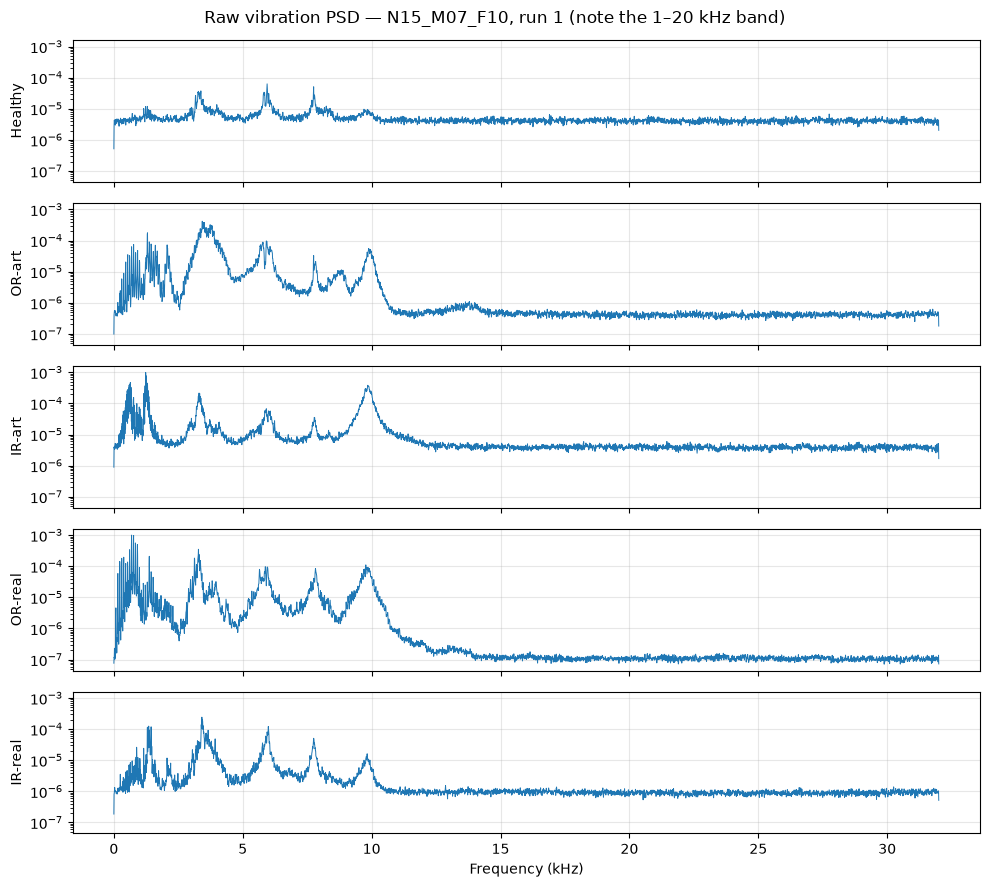

In [2]:
fig, axes = plt.subplots(5, 1, figsize=(10, 9), sharex=True, sharey=True)
for ax, (label, code_) in zip(axes, BEARINGS.items()):
    vib, _, _ = load_run(code_, 1)
    f, pxx = welch(vib, fs=FS_HIGH_HZ, nperseg=1 << 13)
    ax.semilogy(f / 1000, pxx, linewidth=0.7)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Frequency (kHz)")
fig.suptitle(f"Raw vibration PSD — {CONDITION}, run 1 (note the 1–20 kHz band)")
plt.tight_layout()
plt.show()

## Envelope spectrum

The faulty spectra above carry extra energy spread across roughly **1–20 kHz**
— resonances rung by the impacts — but the *repetition rate* of the impacts
(the diagnostic information) is invisible there. Envelope analysis recovers it:

1. band-pass the signal to the resonance region (1–20 kHz),
2. take the amplitude envelope (magnitude of the analytic signal / Hilbert),
3. FFT the envelope and look **below ~400 Hz** for BPFO / BPFI and harmonics.

Expected signatures: outer-race faults → peaks at BPFO and its harmonics
(defect fixed in the load zone, little modulation); inner-race faults → peaks
at BPFI **plus sidebands / a strong component at the shaft frequency fr**,
because the defect rides in and out of the load zone once per revolution.

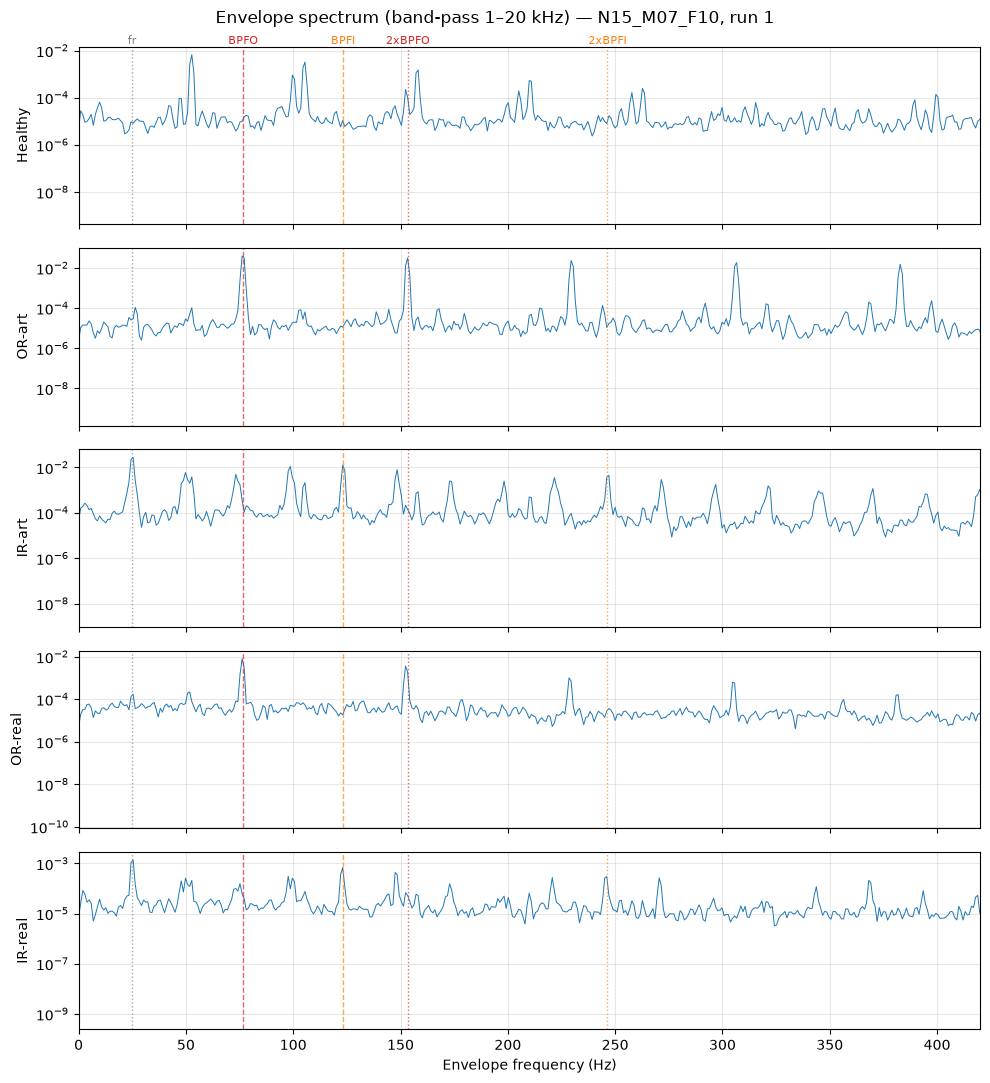

In [3]:
BAND_HZ = (1000, 20000)
SOS_ENV = butter(4, BAND_HZ, btype="bandpass", fs=FS_HIGH_HZ, output="sos")


def envelope(sig):
    env = np.abs(hilbert(sosfiltfilt(SOS_ENV, sig.astype(np.float64))))
    return env - env.mean()


def envelope_spectrum(sig, nperseg=1 << 16):
    return welch(envelope(sig), fs=FS_HIGH_HZ, nperseg=nperseg)


markers = [(bpfo, "BPFO", "tab:red", "--"), (2 * bpfo, "2xBPFO", "tab:red", ":"),
           (bpfi, "BPFI", "tab:orange", "--"), (2 * bpfi, "2xBPFI", "tab:orange", ":"),
           (fr_meas, "fr", "grey", ":")]

fig, axes = plt.subplots(5, 1, figsize=(10, 11), sharex=True)
for ax, (label, code_) in zip(axes, BEARINGS.items()):
    vib, _, _ = load_run(code_, 1)
    f, pxx = envelope_spectrum(vib)
    ax.semilogy(f, pxx, linewidth=0.7, color="tab:blue")
    for freq, name, color, ls in markers:
        ax.axvline(freq, color=color, linestyle=ls, alpha=0.7, linewidth=1)
    ax.set_xlim(0, 420)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
for freq, name, color, ls in markers:
    axes[0].text(freq, axes[0].get_ylim()[1], name, color=color,
                 ha="center", va="bottom", fontsize=8)
axes[-1].set_xlabel("Envelope frequency (Hz)")
fig.suptitle(f"Envelope spectrum (band-pass {BAND_HZ[0]//1000}–{BAND_HZ[1]//1000} kHz) — {CONDITION}, run 1")
plt.tight_layout()
plt.show()

## Quantify it: peak SNR at the fault frequencies

Peak height inside ±3 Hz of each target vs. the local noise floor (median PSD
within ±30 Hz, excluding the peak band) — in dB, per bearing.

In [4]:
def peak_snr_db(f, pxx, target, halfwidth=3.0, noise_width=30.0):
    inband = (f >= target - halfwidth) & (f <= target + halfwidth)
    around = (f >= target - noise_width) & (f <= target + noise_width) & ~inband
    return 10 * np.log10(pxx[inband].max() / np.median(pxx[around]))


targets = {"BPFO": bpfo, "2xBPFO": 2 * bpfo, "BPFI": bpfi,
           "2xBPFI": 2 * bpfi, "fr": fr_meas}
rows = {}
for label, code_ in BEARINGS.items():
    vib, _, _ = load_run(code_, 1)
    f, pxx = envelope_spectrum(vib)
    rows[label] = {name: peak_snr_db(f, pxx, tgt) for name, tgt in targets.items()}
snr_table = pd.DataFrame(rows).T.round(1)
snr_table

,BPFO,2xBPFO,BPFI,2xBPFI,fr
Healthy,0.7,13.9,-1.4,3.2,0.4
OR-art,34.5,33.0,2.4,10.7,9.7
IR-art,12.8,3.9,21.5,18.6,24.7
OR-real,23.0,20.9,1.5,2.8,5.9
IR-real,7.1,6.1,15.2,13.4,17.9


## Reading the envelope results

- **Outer-race faults scream at BPFO**: ~35 dB (artificial) and ~23 dB (real)
  above the floor, with strong harmonics — and essentially nothing at BPFI.
- **Inner-race faults show BPFI + shaft-frequency modulation**: ~21 dB
  (artificial) and ~15 dB (real) at BPFI, plus an fr component (~18–25 dB),
  exactly the load-zone modulation signature expected for a rotating defect.
- **KI04 (IR-real) — the bearing notebook 02 could not tell from healthy —
  is now unambiguous.** Time-domain RMS said "healthy"; the envelope spectrum
  says "inner-race fault, ~15 dB". This is the single most important result of
  this notebook.
- **Caveat — the healthy baseline is not spectrally empty**: K001 carries a
  harmonic family at ≈52.7 Hz (×2 ≈ 105, ×3 ≈ 158 Hz…), a rig-related
  modulation (not a 6203 defect frequency — BSF would be ≈50.9 Hz), plus the
  100 Hz electrical fundamental. The ×3 line at ≈158 Hz sits near
  2×BPFO ≈ 153.5 Hz, which is why the healthy `2xBPFO` cell above is inflated
  (~14 dB). Feature windows must be tight, and the BPFO/BPFI *fundamentals*
  (clean in the healthy row: ≈0 dB) are the trustworthy discriminators.

## MCSA: does the motor current see the bearing faults?

First surprise: the electrical fundamental of this 425 W PMSM at 1500 rpm is
**100 Hz, not 50 Hz** → the machine has 4 pole pairs (f_elec = p · fr = 4 × 25).

Classic MCSA predicts bearing-fault components at `|f_s ± k·f_fault|`
(Schoen et al., 1995). At this operating condition the rig has an unlucky
degeneracy: `BPFO + BPFI = Z·fr = 200 Hz = 2·f_s`, so the *lower* BPFO sideband
and the *lower* BPFI sideband coincide (`100 − 76.7 ≈ 123.2 − 100 ≈ 23.2 Hz`)
— they cannot be told apart. The upper sidebands (176.7 / 223.2 Hz) remain
distinct. We also expect **eccentricity sidebands at f_s ± fr (75 / 125 Hz)**
in *every* bearing, healthy included — a machine signature, not a fault.

Because notebook 02 showed current effects of ~1–2 % at best, we stack the
odds in MCSA's favour: average the PSD over all 20 runs per bearing
(≈80 s of signal) before looking for sidebands.

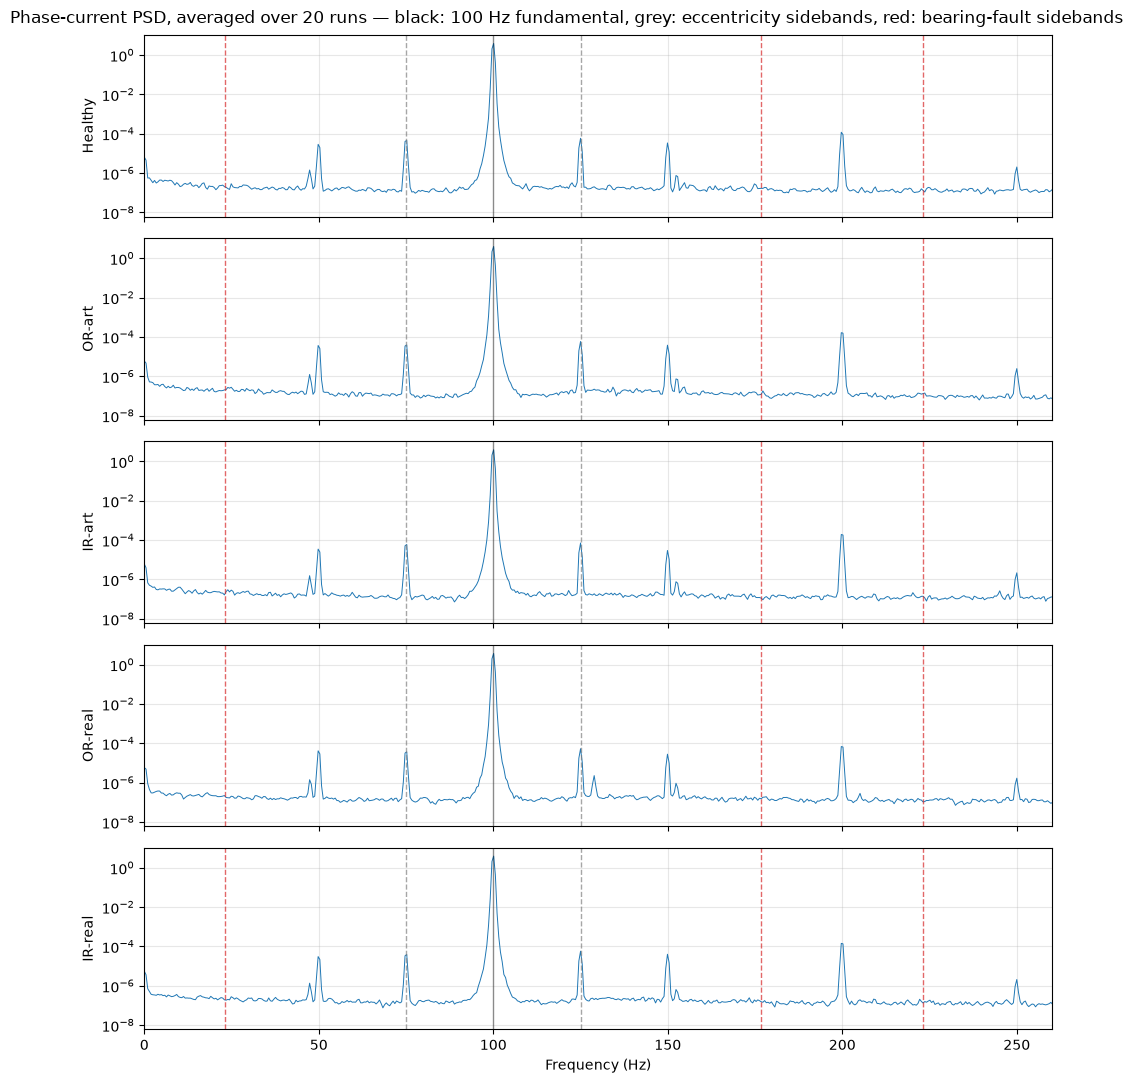

,lower SB (23.2),fs+BPFO (176.7),fs+BPFI (223.2),fs-fr ecc (75),fs+fr ecc (125)
Healthy,1.5,3.0,1.7,25.5,25.1
OR-art,1.5,1.6,1.7,25.7,25.7
IR-art,1.4,0.3,1.2,26.7,26.3
OR-real,0.5,1.3,0.9,24.6,25.0
IR-real,0.8,1.1,2.1,24.3,24.8


In [5]:
mcsa_targets = {
    "lower SB (23.2)": 100.0 - bpfo,   # = bpfi - 100 (degenerate)
    "fs+BPFO (176.7)": 100.0 + bpfo,
    "fs+BPFI (223.2)": 100.0 + bpfi,
    "fs-fr ecc (75)":  100.0 - fr_meas,
    "fs+fr ecc (125)": 100.0 + fr_meas,
}

avg_psd = {}
for label, code_ in BEARINGS.items():
    psds = []
    for run in range(1, 21):
        _, cur, _ = load_run(code_, run)
        f_c, pxx = welch(cur.astype(np.float64), fs=FS_HIGH_HZ, nperseg=1 << 17)
        psds.append(pxx)
    avg_psd[label] = np.mean(psds, axis=0)

fig, axes = plt.subplots(5, 1, figsize=(10, 11), sharex=True, sharey=True)
for ax, (label, pxx) in zip(axes, avg_psd.items()):
    ax.semilogy(f_c, pxx, linewidth=0.7, color="tab:blue")
    for name, tgt in mcsa_targets.items():
        color = "grey" if "ecc" in name else "tab:red"
        ax.axvline(tgt, color=color, linestyle="--", alpha=0.7, linewidth=1)
    ax.axvline(100.0, color="black", linestyle="-", alpha=0.4, linewidth=1)
    ax.set_xlim(0, 260)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Frequency (Hz)")
fig.suptitle("Phase-current PSD, averaged over 20 runs — black: 100 Hz fundamental, "
             "grey: eccentricity sidebands, red: bearing-fault sidebands")
plt.tight_layout()
plt.show()

mcsa_table = pd.DataFrame({
    label: {name: peak_snr_db(f_c, pxx, tgt, halfwidth=2.0, noise_width=15.0)
            for name, tgt in mcsa_targets.items()}
    for label, pxx in avg_psd.items()
}).T.round(1)
mcsa_table

## MCSA verdict: a clean negative result

Even with 20-run PSD averaging (≈80 s of current), **no bearing-fault sideband
rises meaningfully above the noise floor** (all ≤ ~3 dB, healthy included),
while the eccentricity sidebands at 75/125 Hz stand ~25 dB proud **in every
bearing including the healthy one** — i.e. the only strong low-frequency
structure in the current is a machine signature, not a fault indicator.

This is worth stating precisely because it is *honest and citable*: on this
rig, at this operating condition, classic sideband MCSA does not detect these
bearing faults. It matches Lessmeier et al.'s own experience (current-based
diagnosis needed heavy ML and still trailed vibration) and sharpens our
Phase-2 plan: current-channel diagnosis will need **learned features**
(e.g. spectrogram + CNN), not hand-picked sidebands. For the feature table we
still include the sideband SNRs — letting the baseline classifier *confirm*
their uselessness is part of the evidence.

## Spectral feature/target table

Per-window features over all 5 bearings × 20 runs, window = 16 384 samples
(256 ms → 3.9 Hz envelope-bin resolution; 15 windows per run → 1 500 rows).
Per window:

| Feature | Source | Meaning |
|---|---|---|
| `Env_BPFO_dB`, `Env_BPFOh2_dB` | vibration envelope | outer-race peak SNR (fund., 2nd harm.) |
| `Env_BPFI_dB`, `Env_BPFIh2_dB` | vibration envelope | inner-race peak SNR |
| `Env_fr_dB` | vibration envelope | shaft-rate modulation (IR load-zone signature) |
| `Vib_RMS`, `Vib_CrestFactor` | vibration, time domain | notebook-02 continuity |
| `Cur_SBlow_dB`, `Cur_SB_BPFO_dB`, `Cur_SB_BPFI_dB` | current spectrum | MCSA sidebands (expected ≈ useless) |
| `Cur_Ecc_dB` | current spectrum | eccentricity sideband (control: strong everywhere) |
| `Cur_RMS` | current, time domain | notebook-02 continuity |

Targets are recomputed per run from the measured shaft speed (tacho channel),
and each SNR uses the window's own 10–400 Hz median floor — so the features are
speed- and level-normalized by construction.

In [6]:
WIN = 16_384
N_WIN = N_KEEP // WIN  # 15
HANN = get_window("hann", WIN)
WIN_FREQS = np.fft.rfftfreq(WIN, 1 / FS_HIGH_HZ)
FLOOR_MASK = (WIN_FREQS > 10) & (WIN_FREQS < 400)


def band_peak_db(spec, target, floor, halfwidth=4.0):
    band = (WIN_FREQS >= target - halfwidth) & (WIN_FREQS <= target + halfwidth)
    return 10 * np.log10(spec[:, band].max(axis=1) / floor)


def windowed_spectrum(sig):
    w = sig[: N_WIN * WIN].reshape(N_WIN, WIN)
    w = w - w.mean(axis=1, keepdims=True)
    spec = np.abs(np.fft.rfft(w * HANN, axis=1)) ** 2
    return w, spec


def run_features(code_, run):
    vib, cur, fr = load_run(code_, run)
    bpfo_r, bpfi_r = fault_freqs(fr)

    # vibration: envelope-band SNRs + time-domain stats
    _, espec = windowed_spectrum(envelope(vib))
    efloor = np.median(espec[:, FLOOR_MASK], axis=1)
    v = vib[: N_WIN * WIN].reshape(N_WIN, WIN).astype(np.float64)
    vib_rms = np.sqrt(np.mean(v ** 2, axis=1))

    # current: raw-spectrum sideband SNRs + RMS
    c, cspec = windowed_spectrum(cur.astype(np.float64))
    cfloor = np.median(cspec[:, FLOOR_MASK], axis=1)

    return pd.DataFrame({
        "Env_BPFO_dB":   band_peak_db(espec, bpfo_r, efloor),
        "Env_BPFOh2_dB": band_peak_db(espec, 2 * bpfo_r, efloor),
        "Env_BPFI_dB":   band_peak_db(espec, bpfi_r, efloor),
        "Env_BPFIh2_dB": band_peak_db(espec, 2 * bpfi_r, efloor),
        "Env_fr_dB":     band_peak_db(espec, fr, efloor),
        "Vib_RMS":         vib_rms,
        "Vib_CrestFactor": np.abs(v).max(axis=1) / vib_rms,
        "Cur_SBlow_dB":   band_peak_db(cspec, 100.0 - bpfo_r, cfloor),
        "Cur_SB_BPFO_dB": band_peak_db(cspec, 100.0 + bpfo_r, cfloor),
        "Cur_SB_BPFI_dB": band_peak_db(cspec, 100.0 + bpfi_r, cfloor),
        "Cur_Ecc_dB":     band_peak_db(cspec, 100.0 + fr, cfloor),
        "Cur_RMS": np.sqrt(np.mean(c ** 2, axis=1)),
    })


tables = []
for label, code_ in BEARINGS.items():
    for run in range(1, 21):
        feats = run_features(code_, run)
        feats["Status"] = label
        feats["Run"] = run
        tables.append(feats)
dataset = pd.concat(tables, ignore_index=True)
print(f"Total rows: {len(dataset)}  ({len(BEARINGS)} bearings x 20 runs x {N_WIN} windows)")
dataset.sample(6, random_state=0).round(2)

Total rows: 1500  (5 bearings x 20 runs x 15 windows)


,Env_BPFO_dB,Env_BPFOh2_dB,Env_BPFI_dB,Env_BPFIh2_dB,Env_fr_dB,Vib_RMS,Vib_CrestFactor,Cur_SBlow_dB,Cur_SB_BPFO_dB,Cur_SB_BPFI_dB,Cur_Ecc_dB,Cur_RMS,Status,Run
471,26.90,26.36,0.75,-3.81,5.68,0.54,6.77,3.62,-4.24,-5.57,19.80,1.79,OR-art,12
9,0.24,16.43,-1.52,-4.39,3.51,0.40,10.95,0.03,-0.01,-0.33,16.77,1.76,Healthy,1
1499,3.69,1.11,2.88,4.94,10.98,0.38,7.30,-3.01,-5.68,5.15,15.51,1.77,IR-real,20
54,-7.92,14.58,0.61,-5.87,-10.41,0.40,9.61,-2.32,5.02,-4.89,17.41,1.77,Healthy,4
1411,1.25,1.85,10.97,4.15,11.79,0.38,8.62,7.01,-15.33,1.41,18.44,1.78,IR-real,15
1157,18.84,17.79,-0.29,-2.37,0.75,0.50,6.83,3.83,-1.09,-5.15,18.28,1.72,OR-real,18


## The before/after picture

Left: notebook 02's best time-domain view (where IR-real hid inside healthy).
Right: the two envelope fundamentals. If envelope analysis did its job, the
right panel pulls the classes apart along physically meaningful axes:
outer-race classes move right (BPFO), inner-race classes move up (BPFI).
Watch for the one remaining weak spot — per-window IR-real vs healthy —
and check the `Env_fr_dB` column in the mean table below for the axis that
closes it.

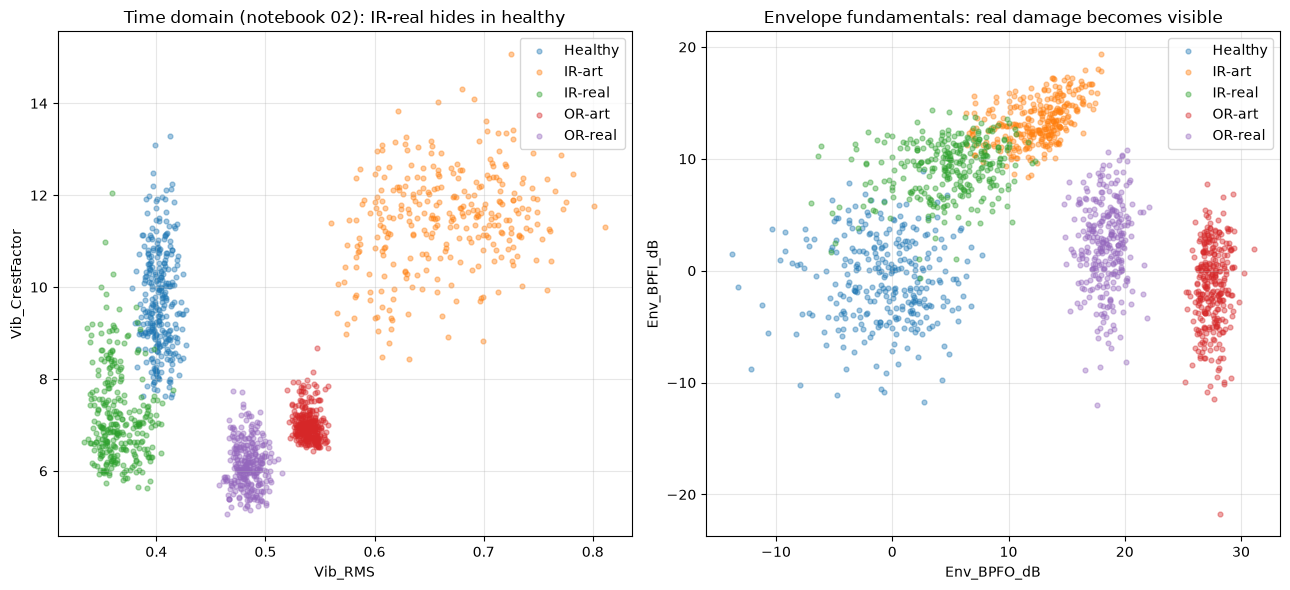

,Env_BPFO_dB,Env_BPFI_dB,Env_fr_dB,Cur_SB_BPFO_dB,Cur_Ecc_dB
Status,,,,,
Healthy,-0.7,-0.8,0.2,-0.6,17.1
IR-art,12.5,13.4,18.3,-0.9,18.0
IR-real,4.8,9.1,13.1,-0.8,17.1
OR-art,27.5,-1.5,2.6,-0.5,18.1
OR-real,18.3,2.3,3.7,-0.3,17.1


In [7]:
fig, (ax_t, ax_f) = plt.subplots(1, 2, figsize=(13, 6))
for label, group in dataset.groupby("Status"):
    ax_t.scatter(group["Vib_RMS"], group["Vib_CrestFactor"], label=label, alpha=0.4, s=12)
    ax_f.scatter(group["Env_BPFO_dB"], group["Env_BPFI_dB"], label=label, alpha=0.4, s=12)
ax_t.set_xlabel("Vib_RMS")
ax_t.set_ylabel("Vib_CrestFactor")
ax_t.set_title("Time domain (notebook 02): IR-real hides in healthy")
ax_f.set_xlabel("Env_BPFO_dB")
ax_f.set_ylabel("Env_BPFI_dB")
ax_f.set_title("Envelope fundamentals: real damage becomes visible")
for ax in (ax_t, ax_f):
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

dataset.groupby("Status")[["Env_BPFO_dB", "Env_BPFI_dB", "Env_fr_dB",
                           "Cur_SB_BPFO_dB", "Cur_Ecc_dB"]].mean().round(1)

In [8]:
OUT = pathlib.Path("../data/processed")
OUT.mkdir(parents=True, exist_ok=True)
csv_path = OUT / f"pu_{CONDITION}_spectral_features.csv"
dataset.to_csv(csv_path, index=False)
print(f"saved {len(dataset)} rows x {dataset.shape[1]} cols -> {csv_path}")

saved 1500 rows x 14 cols -> ..\data\processed\pu_N15_M07_F10_spectral_features.csv


## Findings (executed 2026-07-30)

1. **Envelope analysis recovers what time-domain features missed.** Peak SNR
   at the fault frequencies (whole-signal, run 1): OR-art **+34.5 dB** and
   OR-real **+23.0 dB** at BPFO; IR-art **+21.5 dB** and IR-real **+15.2 dB**
   at BPFI — healthy sits at ≈0 dB on both fundamentals. **KI04 (IR-real),
   indistinguishable from healthy in notebook 02, now shows an unambiguous
   +15 dB inner-race signature plus +18 dB shaft-rate modulation.** The same
   holds per window (means: Env_BPFI 9.1 dB IR-real vs −0.8 healthy; Env_fr
   13.1 vs 0.2), with only a thin per-window IR-real↔healthy contact zone in
   the 2-D scatter that the Env_fr axis closes.
2. **Artificial > real severity ordering persists in the frequency domain**
   (34.5 vs 23.0 dB at BPFO; 21.5 vs 15.2 dB at BPFI): EDM damage rings
   louder and cleaner than real fatigue damage. The notebook-02 domain gap is
   still there — but now *both* domains are detectable, so the upcoming
   artificial→real classifier test measures **transfer**, not feature
   blindness. That was the precondition for a meaningful RQ4 number.
3. **MCSA is a clean negative result.** The electrical fundamental is
   **100 Hz (4 pole pairs), not 50 Hz**; with correct targets and 20-run PSD
   averaging, no bearing-fault sideband exceeds ~3 dB in any bearing, while
   eccentricity sidebands (f_s ± fr) stand ~25 dB proud in *all* bearings,
   healthy included. Bonus trap on this rig/condition:
   BPFO + BPFI = Z·fr ≈ 200 Hz = 2·f_s, so the lower BPFO/BPFI sidebands
   coincide at 23.2 Hz. Conclusion: current-channel diagnosis needs learned
   features (Phase 2), not hand-picked sidebands — consistent with Lessmeier
   et al.'s own results.
4. **The healthy baseline is not spectrally empty** — a ≈52.7 Hz rig harmonic
   family (×3 ≈ 158 Hz, near 2×BPFO = 153.5) inflates healthy's `2xBPFO`
   reading to ~14 dB. Harmonic features are contaminated; the BPFO/BPFI
   **fundamentals** are the trustworthy discriminators. Rule adopted: every
   feature gets sanity-checked against the healthy row before use.
5. **Deliverable:** 1 500 rows × 14 columns saved to
   `data/processed/pu_N15_M07_F10_spectral_features.csv` — speed-normalized
   (targets from the tacho channel) and level-normalized (dB vs per-window
   floor) by construction. This is the input for the Random-Forest
   artificial→real baseline.